### ELO328 - Procesamiento Digital de Imágenes
# Clase 16: Morfología
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Morfología

- Conjunto de técnicas que permiten cambiar la forma de una región de manera controlada.
- Se basa en la teoría de conjuntos, donde un conjunto representa a objetos en una imagen.
- Útil para representación y descripción de la forma de una región:
    - Bordes.
    - Esqueleto.
    - Envoltura convexa (convex hull).
    - Filtrado.
    - Adelgazamiento.
    - Clasificación.

# Operaciones básicas sobre conjuntos

<div align="center">
    <img src="img/conjuntos.png" alt="" width="50%" align="center" />
</div>

# Otras operaciones sobre conjuntos

- La **reflexión** de $B$ se define como:

$$ \hat{B} = \{ x | x = -b, b \in B \} $$

- La **traslación** de $B$ por $z$ se define como:

$$ B_z = \{ x | x = b + z, b \in B \} $$

<div align="center">
    <img src="img/trasreflex.jpg" alt="" width="30%" align="center" />
</div>

# Operaciones Morfológicas

- La idea básica en morfología es utilizar una forma simple $B$, pre-definida, para aplicar una operación de conjuntos sobre una imagen binaria $A$.
- Esta forma simple es llamada el "elemento estructurante" (`footprint`), y también es una imagen binaria.
- Puede tener distintas formas. Algunos ejemplos de las más usadas son: Disco, Cuadrado, Cruz, etc.
- El elemento estructurante posee un centro, que corresponde al punto de aplicación de la operación morfológica.

# Structural Element

<div align="center">
    <img src="img/StructuralElement.png" alt="" width="40%" align="center" />
</div>

# Ejemplo en Python

Ejemplo de `footprint` en forma de disco con radio 6:

In [1]:
from skimage.morphology import disk 

In [2]:
footprint = disk(radius=6)

In [3]:
footprint

array([[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
       [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]], dtype=uint8)

# Dilatación

Dada una imagen $A$, y un elemento estructural $B$, (ambos imágenes binarias con fondo blanco), la dilatación de $A$ por $B$ se define como: 

$$ A \oplus B = \{ x | \hat{B}_x  \cap A  \neq \varnothing \} $$

Es decir, cualquier desplazamiento del centro de $B$ que entregue una intersección no vacía con $A$.

La dilatación agranda las regiones brillantes y reduce las regiones oscuras.

<div align="center">
    <img src="img/dilatacion.jpg" alt="" width="40%" align="center" />
</div>

# Ejemplo en Python

In [4]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.util import img_as_ubyte

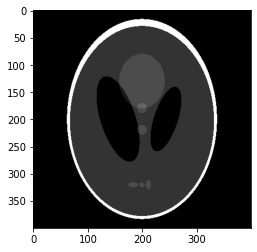

In [5]:
orig_phantom = img_as_ubyte(data.shepp_logan_phantom())
fig, ax = plt.subplots()
ax.imshow(orig_phantom, cmap=plt.cm.gray);

In [6]:
def plot_comparison(img1, img2, operation):
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(8, 4), sharex=True, sharey=True)
    ax1.imshow(img1, cmap=plt.cm.gray)
    ax1.set_title('Original')
    ax1.axis('off')
    ax2.imshow(img2, cmap=plt.cm.gray)
    ax2.set_title(operation)
    ax2.axis('off')

In [7]:
from skimage.morphology import dilation

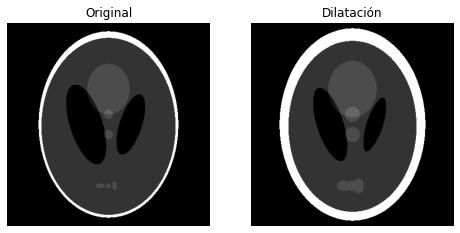

In [8]:
dilated = dilation(orig_phantom, footprint)
plot_comparison(orig_phantom, dilated, 'Dilatación')

# Erosión

Dada una imagen $A$, y un elemento estructural $B$, (ambos imágenes binarias con fondo blanco), la erosión de $A$ por $B$ se define como: 

$$ A \ominus B = \{ x | B_x  \subseteq A \} $$

Es decir, cualquier desplazamiento del centro de $B$ tal que la traslación de $B$ esté completamente dentro de $A$.

<div align="center">
    <img src="img/erosion.jpg" alt="" width="40%" align="center" />
</div>

In [9]:
from skimage.morphology import erosion

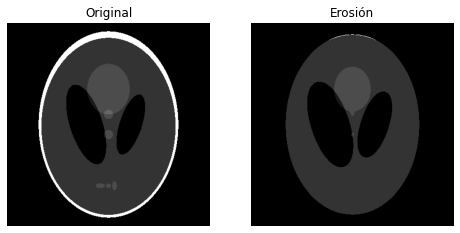

In [10]:
eroded = erosion(orig_phantom, footprint)
plot_comparison(orig_phantom, eroded, 'Erosión')

# Apertura

Dada una imagen $A$, y un elemento estructural $B$, la apertura de $A$ por $B$ se define como: 

$$ A \circ B = (A \ominus B) \oplus B $$

que, en palabras, establece que la apertura de $A$ por $B$ es simplemente la erosión de $A$ por $B$, seguido de la dilatación del resultado por $B$. 

La apertura generalmente suaviza los contornos de una imagen y elimina pequeños salientes. También puede eliminar franjas o zonas de un objeto que sean “más estrechas” que el elemento estructural.

La apertura puede eliminar pequeños puntos brillantes (es decir, ruido "sal") y conectar pequeñas grietas oscuras.

In [11]:
from skimage.morphology import opening

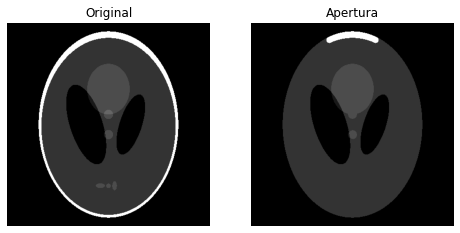

In [12]:
opened = opening(orig_phantom, footprint)
plot_comparison(orig_phantom, opened, 'Apertura')

# Clausura o Cierre

Dada una imagen $A$, y un elemento estructural $B$, la apertura de $A$ por $B$ se define como: 

$$ A \bullet   B = (A \oplus B) \ominus B $$

que, en palabras, establece que la clausura de $A$ por $B$ es simplemente la dilatación de $A$ por $B$, seguido de la erosión del resultado por $B$. 

El cierre puede eliminar pequeñas manchas oscuras (es decir, ruido "pimienta") y conectar pequeñas grietas brillantes.

In [13]:
from skimage.morphology import closing

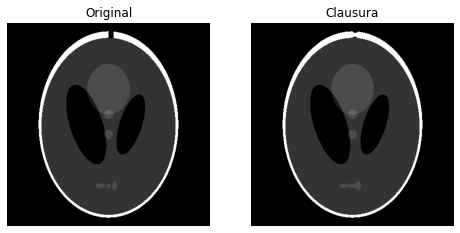

In [14]:
# Para ilustrar como la Clausura conecta grietas se agrega una pequeña grieta al borde blanco
phantom = orig_phantom.copy()
phantom[10:30, 200:210] = 0

closed = closing(phantom, footprint)
plot_comparison(phantom, closed, 'Clausura')

<div align="center">
    <img src="img/aperturaclausura.jpg" alt="" width="40%" align="center" />
</div>

# Trasformada Hit-and-Miss (aka hit-or-miss)

Dada una imagen $A$, y un elemento estructural compuesto $B=(C,D)$, donde $C$ y $D$ son dos elementos estructurales tales que $C \cap D = \emptyset$, la transformada Hit-and-Miss de $A$ por $B$ está dada por:

$$ A * B=(A\ominus C)\cap(A^c\ominus D) $$


Por definición, la transformación hit-or-miss indica las posiciones en las que se produce un determinado patrón (caracterizado por el elemento estructurante compuesto $B$) en la imagen de entrada. Es decir, se puede usar para buscar una determinada configuración en los píxeles negros y blancos.

El elemento estructurante C indica que configuración de píxeles se está buscando en primer plano y D indica que píxeles se desea evitar (o dicho de otro modo, busca en el fondo).

<div align="center">
    <img src="img/HitMiss.jpg" alt="" width="45%" align="center" />
</div>

En el ejemplo anterior, se asume que los píxeles negros pertenecen al fondo de la imagen y la "X" indica que estos píxeles pueden ser indistinguiblemente blancos o negros (no interesan).

# Ejemplo

Supongamos que queremos encontrar en la imagen $A$ un patrón con forma de T, definido por el elemento estructural $C1$, pero que no contenga el patrón definido por el elemento estructural $D1$.

<div align="center">
    <img src="img/A.png" alt="" width="10%" align="left" />
    <img src="img/HitOrMissEx.png" alt="" width="40%" align="center" />
</div>

In [15]:
import numpy as np
from scipy import ndimage

In [16]:
A = np.array((
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 255, 255, 255, 0, 255, 255, 255],
    [0, 0, 255, 255, 0, 0, 255, 0],
    [0, 0, 255, 255, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 255, 255, 255, 0, 255, 255, 255],
    [0,255, 255, 0, 0, 0, 255, 0],
    [0, 255, 255, 0, 0, 0, 255, 0]), dtype="uint8")

In [17]:
C = np.array((
        [1, 1, 1],
        [0, 1, 0],
        [0, 1, 0]), dtype="int")

D = np.array((
        [0, 0, 0],
        [0, 0, 1],
        [0, 0, 1]), dtype="int")

In [18]:
hit = ndimage.binary_hit_or_miss(A, structure1=C, structure2=D).astype(int)

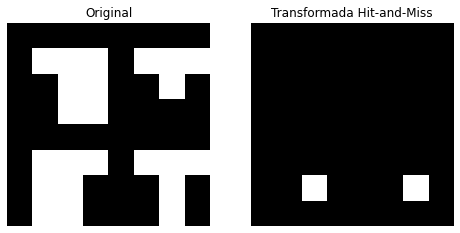

In [19]:
plot_comparison(A, hit, 'Transformada Hit-and-Miss')

# Adelgazamiento

El adelgazamiento de una imagen $A$ a partir de un elemento estructural $B$ se define como:

$$ A \otimes B = A - (A * B) = A \cap (A * B)^C $$

In [20]:
from skimage.morphology import thin

In [21]:
from skimage.util import invert
horse = invert(data.horse())

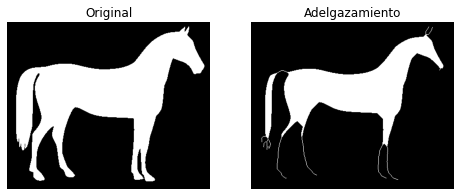

In [22]:
thinned = thin(horse, max_num_iter=10)
plot_comparison(horse, thinned, 'Adelgazamiento')

# Engrosamiento

El engrosamiento de una imagen $A$ a partir de un elemento estructural $B$ se define como:

$$ A \odot B = A \cup (A * B) $$

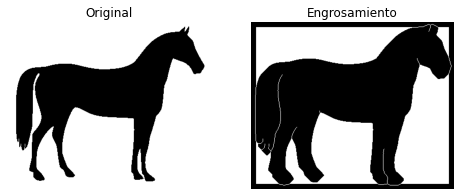

In [23]:
thickening = thin(data.horse(), max_num_iter=10)
plot_comparison(data.horse(), thickening, 'Engrosamiento')

# Esqueleto

Como sugiere el nombre, esta técnica se utiliza para reducir la imagen a un esqueleto de 1 píxel de ancho mediante la aplicación de adelgazamientos sucesivos. Es importante tener en cuenta que esto se realiza solo en imágenes binarias.

El esqueleto de una imagen $A$ puede ser expresado en términos de erosiones y aperturas.  

$$ S(A) = \bigcup_{k=0}^{K} S_k(A)  $$

con $S_k(A) = (A \ominus kB) - (A \ominus kB) \circ B  $, donde $B$ es un elemento estructural y $(A \ominus kB)$ indica $k$ erosiones sucesivas $( ( \dots ((A \ominus B) \ominus B) \ominus \dots ) \ominus B )$.

In [24]:
from skimage.morphology import skeletonize

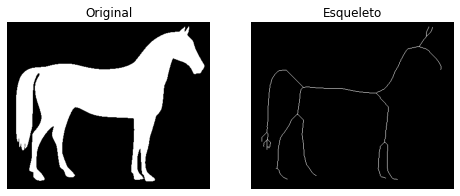

In [25]:
sk = skeletonize(horse)
plot_comparison(horse, sk, 'Esqueleto')

# Convex Hull

Convex Hull es el conjunto de píxeles incluidos en el polígono convexo más pequeño que rodea todos los píxeles blancos en la imagen de entrada.

In [26]:
from skimage.morphology import convex_hull_image  

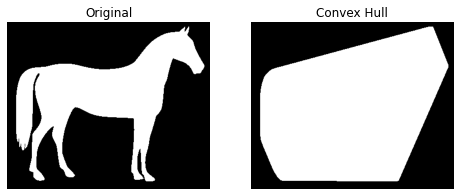

In [27]:
hull = convex_hull_image(horse)
plot_comparison(horse, hull, 'Convex Hull')